# A Reassessment of Monetary Policy Surprises and High-Frequency Identification

Michael D. Bauer and Eric T. Swanson, *NBER Macroeconomics Annual* 2022, vol. 37 (2023).

Replication by **Isabella Bonetto, Irene Ferraioli, Lorenzo Giordani, Alessio Morrone, Tiziano Nocco**.

**What this notebook replicates**, with the authors' published data (`data/monetary-policy-surprises-data.xlsx`, original 2022 release):
- **Table 1**, columns (1)–(3): high-frequency monetary policy surprises are predictable from macro and financial data known before the announcement.
- **The orthogonalized instrument**: the monthly surprises and their orthogonalized version, rebuilt from scratch and checked against the authors' series.
- **Figure 3**: a proxy SVAR identified with the raw surprise versus the orthogonalized surprise, with wild-bootstrap bands and first-stage F statistics.
- **Figure 2**: the same SVAR over the paper's three sample periods.

**What it cannot replicate.** The results with Fed Chair speeches (Section 5.1.4, Figure 4 onwards) need the speech surprises, which the authors have not released (see the `Description` sheet). Table 2 needs Greenbook and Blue Chip forecasts, and column (4) of Table 1 needs the FF4 surprise; neither is in the file.

**Contents.**
1. The argument in brief
2. Setup
3. Predictability of the surprises (Table 1)
4. From announcements to a monthly instrument
5. The reduced-form VAR
6. Identification with an external instrument
7. Wild-bootstrap bands
8. Raw versus orthogonalized instrument (Figure 3)
9. Sample periods (Figure 2)

## 1. The argument in brief

**High-frequency identification.** Measure how interest-rate futures move in a 30-minute window around each FOMC announcement (10 minutes before to 20 after). In such a short window nothing else is news, so the change is a *monetary policy surprise*. Bauer and Swanson's measure, `mps`, is the first principal component of the changes in the first four Eurodollar futures (ED1–ED4), scaled so that its effect on ED4 is one. These surprises serve as an external instrument for the monetary policy shock in SVARs and local projections (Stock and Watson, 2012, 2018; Gertler and Karadi, 2015).

**The problem.** An instrument $z_t$ for the policy shock $\varepsilon_{1t}$ must be
- **relevant**, $E[z_t\varepsilon_{1t}] \ne 0$, and
- **exogenous**, $E[z_t\varepsilon_{2t}] = 0$ for every other shock $\varepsilon_{2t}$.

The surprises turn out to be **correlated with data released before the announcement**: strong payrolls, rising stocks and commodity prices predict hawkish surprises.

**Why the surprises are predictable (the paper's Section 2).** Let $x_t$ be the state of the economy (say, the output gap) and let the Fed follow $i_t = \alpha_t x_t + \varepsilon_t$, where its responsiveness $\alpha_t$ drifts over time. The public observes $x_t$ but not $\alpha_t$: it holds a belief $a_t$, expects $a_t x_t$, and updates $a_t$ by Bayesian learning after every decision. The surprise is then

$$mps_t = i_t - a_t x_t = (\alpha_t - a_t)\,x_t + \varepsilon_t .$$

Since $a_t$ is the best forecast given past data, $E[mps_t \mid x_t, \text{past}] = 0$: the surprise is unpredictable **ex ante**. But if the public underestimates the Fed for a while ($\alpha_t > a_t$), then $\mathrm{Cov}(mps_t, x_t) = (\alpha_t - a_t)\,\mathrm{Var}(x_t) > 0$ over that sample, and the surprise is correlated with the economy **ex post**. Consistent with this, the paper reports that the predictability largely disappears out of sample.

**Not private information.** Miranda-Agrippino and Ricco (2021) read the predictability as a "Fed information effect": the surprises would reveal the Fed's private forecasts (its Greenbook). Bauer and Swanson find that the public Blue Chip forecasts predict the surprises just as well (their Table 2, which needs data not in our file). So the predictability need not come from information only the Fed has. The bias described next can even create the illusion of an information effect (footnote 44).

Whatever its source, the part of $z_t$ that reflects news about the economy is correlated with the non-policy shocks. This violates exogeneity and biases the estimated effects toward zero, or even reverses their sign: good news raises rates *and* output.

**The fix, and its cost.** Regress the surprise on the pre-announcement news and keep the residual, $z_t^\perp$. This restores exogeneity with respect to that news. It does **not** help relevance: it throws away part of the variation in $z_t$, and in the SVAR the first-stage F statistic falls from 8.19 to 1.83, a weak instrument (Section 5.1.3). This is why the paper then adds surprises around Fed Chair speeches, which raise the F statistic from 8.19 to 30.4 for the raw instrument and from 1.83 to 12.4 for the orthogonalized one (Section 5.1.4).

**The results.** With the orthogonalized instrument, the effects of monetary policy on output, prices and credit spreads are about **four times larger** than with the raw one, and the response of the policy rate is much less persistent.

## 2. Setup

The settings follow the paper: 12 monthly lags, a shock that raises the 2-year yield by 25bp on impact, and the six predictors of Table 1. Responses are shown for 48 months. `NREP` sets the bootstrap replications: 2,000 here, against 10,000 in the paper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from pathlib import Path

# ---- settings ----
DATA_FILE = "data/monetary-policy-surprises-data.xlsx"
P = 12                          # VAR lags, months
H = 48                          # IRF horizon, months
SHOCK = 0.25                    # policy shock: +25bp on the 2-year yield on impact
NREP = 2000                     # bootstrap replications (the paper uses 10,000)
SEED = 1234
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
PRED = ["NFP_SURP", "NFP_12M", "SP500_3M", "SLOPE_3M", "BCOM_3M", "TR_SKEW"]
BLUE, ORANGE = "#1f4e79", "#c55a11"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.6,
})

## 3. Predictability of the surprises (Table 1)

For each FOMC announcement $t$, regress the surprise on six predictors known beforehand:

$$\text{mps}_t = \alpha + \beta' X_{t-} + u_t .$$

| Predictor | Column | Definition |
|---|---|---|
| Nonfarm payrolls | `NFP_SURP` | surprise in the latest payrolls release (thousands; divided by 1,000 below to match the paper's units) |
| Employment growth | `NFP_12M` | 12-month log change in payrolls ×100 |
| S&P 500 | `SP500_3M` | log change over the previous 3 months |
| Yield-curve slope | `SLOPE_3M` | change over the previous 3 months |
| Commodity prices | `BCOM_3M` | log change of the Bloomberg spot index over 3 months |
| Treasury skewness | `TR_SKEW` | option-implied skewness of the 10-year yield (Bauer and Chernov) |

As in the paper, the announcement of 17 September 2001 is dropped: markets were closed after 9/11 and it cannot be separated from the attacks. The t-statistics are heteroskedasticity-robust (HC0).

In [2]:
fomc = pd.read_excel(DATA_FILE, sheet_name="FOMC (original)")
fomc = fomc[fomc["Date"] != "2001-09-17"].dropna(subset=["MPS"] + PRED)
fomc["NFP_SURP"] = fomc["NFP_SURP"] / 1000

def table1(d):
    r = sm.OLS(d["MPS"], sm.add_constant(d[PRED])).fit(cov_type="HC0")
    return r

samples = {"(1) 1988–2019": ("1988-01-01", "2019-12-31"),
           "(2) 1994–2019": ("1994-01-01", "2019-12-31"),
           "(3) 1988–2007:6": ("1988-01-01", "2007-06-30")}
PAPER_T1 = {  # coefficient, t-statistic, R2 and N from Table 1 of the paper
    "(1) 1988–2019": ([0.094, 0.005, 0.084, -0.010, 0.119, 0.032], [2.425, 2.144, 1.446, -1.393, 2.380, 3.017], 0.162, 322),
    "(2) 1994–2019": ([0.113, 0.004, 0.112, -0.010, 0.093, 0.035], [1.977, 1.402, 1.578, -1.154, 1.461, 2.917], 0.173, 218),
    "(3) 1988–2007:6": ([0.082, 0.005, 0.154, -0.011, 0.224, 0.050], [1.788, 1.217, 1.943, -1.035, 3.489, 2.127], 0.192, 216),
}
rows = {}
for name, (a, b) in samples.items():
    r = table1(fomc[(fomc["Date"] >= a) & (fomc["Date"] <= b)])
    pc, pt, pr2, pn = PAPER_T1[name]
    col = {f"{v}": f"{r.params[v]:.3f} ({r.tvalues[v]:.2f})" for v in PRED}
    col.update({"R²": f"{r.rsquared:.3f}", "N": int(r.nobs)})
    rows[name + " ours"] = col
    ref = {f"{v}": f"{c:.3f} ({t:.2f})" for v, c, t in zip(PRED, pc, pt)}
    ref.update({"R²": f"{pr2:.3f}", "N": pn})
    rows[name + " paper"] = ref
pd.DataFrame(rows)

,(1) 1988–2019 ours,(1) 1988–2019 paper,(2) 1994–2019 ours,(2) 1994–2019 paper,(3) 1988–2007:6 ours,(3) 1988–2007:6 paper
NFP_SURP,0.094 (2.43),0.094 (2.42),0.113 (1.98),0.113 (1.98),0.082 (1.79),0.082 (1.79)
NFP_12M,0.005 (2.14),0.005 (2.14),0.004 (1.40),0.004 (1.40),0.005 (1.22),0.005 (1.22)
SP500_3M,0.084 (1.45),0.084 (1.45),0.112 (1.58),0.112 (1.58),0.154 (1.94),0.154 (1.94)
SLOPE_3M,-0.010 (-1.39),-0.010 (-1.39),-0.010 (-1.15),-0.010 (-1.15),-0.011 (-1.04),-0.011 (-1.03)
BCOM_3M,0.119 (2.38),0.119 (2.38),0.093 (1.46),0.093 (1.46),0.224 (3.49),0.224 (3.49)
TR_SKEW,0.032 (3.02),0.032 (3.02),0.035 (2.92),0.035 (2.92),0.050 (2.13),0.050 (2.13)
R²,0.162,0.162,0.173,0.173,0.192,0.192
N,322,322,218,218,216,216


## 4. From announcements to a monthly instrument

The SVAR is monthly, so the surprises are aggregated as the authors do (`Description` sheet):
- **Monthly surprise $z_t$:** the sum of all FOMC surprises in the month, and **zero** in the months of 1988–2019 without an announcement.
- **Orthogonalized surprise $z_t^\perp$:** the residual from regressing the monthly surprise on the six predictors, over the months with an announcement. The predictors are those of the month's first announcement. It is zero in months without an announcement.

We rebuild $z_t^\perp$ from these rules and check it against the authors' series.

In [3]:
monthly = pd.read_excel(DATA_FILE, sheet_name="Monthly (original)", index_col=0)
monthly.index = pd.DatetimeIndex(monthly.index).to_period("M")
w = monthly.loc["1988-01":"2019-12"]

has_fomc = w[PRED].notna().all(axis=1)
first = sm.OLS(w.loc[has_fomc, "MPS"], sm.add_constant(w.loc[has_fomc, PRED])).fit()
z_orth = pd.Series(0.0, index=w.index)
z_orth[has_fomc] = first.resid
z_orth[w["MPS"].isna()] = np.nan                  # 1988:1, before the first announcement in the data
z_raw = w["MPS"]

print(f"months with an FOMC announcement: {has_fomc.sum()} of {len(w)};  monthly R² of the orthogonalization: {first.rsquared:.3f}")
print(f"max |our z_orth − authors' MPS_ORTH| = {np.nanmax(np.abs(z_orth - w['MPS_ORTH'])):.1e}")
print(f"share of the variance of z removed by the orthogonalization: {1 - z_orth.var() / z_raw.var():.1%}")

months with an FOMC announcement: 266 of 384;  monthly R² of the orthogonalization: 0.204
max |our z_orth − authors' MPS_ORTH| = 1.1e-04
share of the variance of z removed by the orthogonalization: 20.4%


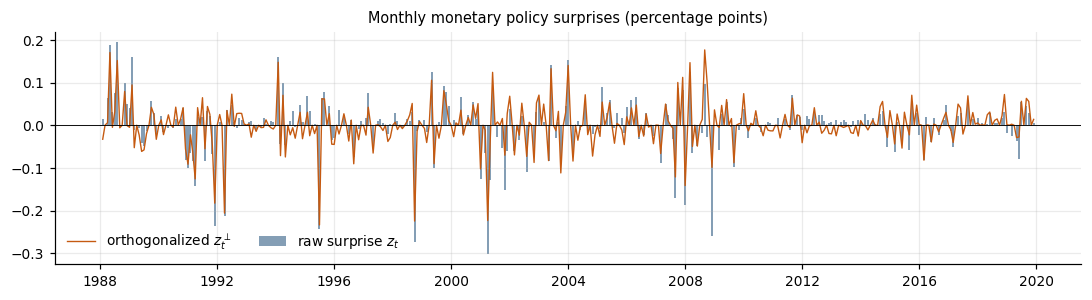

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.8))
t = z_raw.index.to_timestamp()
ax.bar(t, z_raw, width=25, color=BLUE, alpha=0.55, label="raw surprise $z_t$")
ax.plot(t, z_orth, color=ORANGE, lw=0.9, label=r"orthogonalized $z_t^\perp$")
ax.axhline(0, color="k", lw=0.6)
ax.set_title("Monthly monetary policy surprises (percentage points)")
ax.legend(frameon=False, loc="lower left", ncol=2)
ax.xaxis.set_major_locator(mdates.YearLocator(4)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
fig.savefig(FIG / "instrument.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. The reduced-form VAR

As in the paper (Section 5.1.1), a monthly VAR with a constant and 12 lags, estimated by OLS from **1973:1 to 2020:2**. The sample starts when the excess bond premium becomes available, and it ends before the Covid swings in industrial production. The variables are ordered with the policy indicator last:

$$Y_t = \big[\,100\log IP_t,\; 100\log CPI_t,\; EBP_t,\; i^{2y}_t\,\big]', \qquad Y_t = \alpha + \sum_{j=1}^{12} A_j Y_{t-j} + u_t,\qquad E[u_tu_t'] = \Omega .$$

- $EBP$ is the Gilchrist–Zakrajšek excess bond premium.
- $i^{2y}$ is the end-of-month 2-year Treasury yield from the Gürkaynak–Sack–Wright database. It stayed free to move during the 2009–15 zero lower bound, so it measures the policy stance better than the funds rate.

The series are taken from the authors' `Monthly (original)` sheet. With $100\log$, the responses of IP and CPI read in percent, and the other two in percentage points.

The IRFs come from the companion form, exactly as in the CEE notebook. For an impact vector $s_1$,

$$\frac{\partial Y_{t+h}}{\partial\varepsilon_{1t}} = J\mathbf A^h J' s_1,$$

where $\mathbf A$ is the companion matrix and $J = [\,I_4\;0\,\cdots\,0\,]$.

In [5]:
VARS = ["IP", "CPI", "EBP", "2Y yield"]
Ydf = pd.DataFrame({
    "IP": 100 * np.log(monthly["IP"]),
    "CPI": 100 * np.log(monthly["CPI"]),
    "EBP": monthly["EBP"],
    "2Y yield": monthly["2y Treas"],
}).loc["1973-01":"2020-02"]
assert Ydf.notna().all().all()

def lag_matrix(Y, p):
    T = Y.shape[0]
    return np.hstack([np.ones((T - p, 1))] + [Y[p - i:T - i] for i in range(1, p + 1)])

def estimate_var(Y, p):
    X = lag_matrix(Y, p)
    B = np.linalg.lstsq(X, Y[p:], rcond=None)[0]
    return B, Y[p:] - X @ B

def companion(B, m, p):
    A = np.zeros((m * p, m * p))
    A[:m] = B[1:].T
    A[m:, :-m] = np.eye(m * (p - 1))
    return A

def irf(B, s1, p, h):
    m = len(s1)
    A = companion(B, m, p)
    out, state = np.zeros((h + 1, m)), np.zeros(m * p)
    state[:m] = s1
    for k in range(h + 1):
        out[k] = state[:m]
        state = A @ state
    return out

Y = Ydf.values
B, U = estimate_var(Y, P)
res_index = Ydf.index[P:]                                  # dates of the residuals
print(f"VAR: {len(res_index)} monthly observations, {res_index[0]}–{res_index[-1]}; largest companion root "
      f"{np.abs(np.linalg.eigvals(companion(B, 4, P))).max():.4f}")

from statsmodels.tsa.api import VAR
print("max |B − B_statsmodels| =", np.abs(B - VAR(Y).fit(P, trend="c").params).max())

VAR: 554 monthly observations, 1974-01–2020-02; largest companion root 0.9970
max |B − B_statsmodels| = 0.0


## 6. Identification with an external instrument

Write $u_t = S\varepsilon_t$, with orthogonal structural shocks, and split $S = [\,s_1\;S_2\,]$, so that $u_t = s_1\varepsilon_{1t} + S_2\varepsilon_{2t}$. Multiply by the demeaned instrument and take expectations. Relevance and exogeneity give

$$E\big[u_t(z_t-\bar z)\big] = s_1\,E\big[\varepsilon_{1t}(z_t-\bar z)\big] + S_2\underbrace{E\big[\varepsilon_{2t}(z_t-\bar z)\big]}_{=\,0} = \phi\,s_1 .$$

So the covariance between the residuals and the instrument points in the direction of $s_1$. Only the scale $\phi$ is unknown. We fix it the way the paper does: **the shock raises the 2-year yield by 25bp on impact**. This gives

$$\hat s_1 = 0.25\cdot\frac{\widehat{\mathrm{Cov}}(u_t, z_t)}{\widehat{\mathrm{Cov}}(u^{2y}_t, z_t)} .$$

Each element is the IV estimate of a regression of $u_{it}$ on $u^{2y}_t$ with $z_t$ as the instrument. The paper writes the estimator as a single two-stage least squares regression of $Y_t$ on its lags and on $Y^{2y}_t$, instrumented by $z_t$ (equation 22); its footnote 46 notes that regressing the residuals, as we do, gives the same point estimates. The alternative normalisation to a unit-variance shock, $s_1 = v/\sqrt{v'\Omega^{-1}v}$ with $v = E[u_tz_t]$, has the same direction. It follows because $S^{-1}s_1 = e_1$ implies $s_1'\Omega^{-1}s_1 = 1$.

**What the shock is.** The instrument is built from ED1–ED4, so the identified shock is a change in the expected path of short-term rates over the next four quarters. That includes a change in the current funds rate and some forward guidance (Section 5.1.1).

The instrument exists only for 1988–2019, while the VAR runs from 1973. That is fine: the covariances use the months where both are observed, and the VAR dynamics use the whole sample (Stock and Watson, 2018).

**Relevance.** The paper's check is the first-stage F statistic: the squared robust t-statistic of $z_t$ in a regression of the 2-year yield on a constant, 12 lags of $Y_t$ and $z_t$ (footnote 52). The rule of thumb for a weak instrument is $F < 10$.

In [6]:
def impact_vector(U, z):
    # s1 scaled to +25bp on the 2-year yield; U and z are already aligned and complete
    zc = z - z.mean()
    s = U.T @ zc / (U[:, -1] @ zc)
    return SHOCK * s

def first_stage_F(Y, z_on_res_index, p):
    X = lag_matrix(Y, p)
    ok = z_on_res_index.notna().values
    fit = sm.OLS(Y[p:, -1][ok], np.column_stack([X[ok], z_on_res_index.values[ok]])).fit(cov_type="HC0")
    return fit.tvalues[-1] ** 2

instruments = {"raw  z": z_raw, "orth z⊥": z_orth}
S1, F = {}, {}
for name, z in instruments.items():
    zr = z.reindex(res_index)
    ok = zr.notna().values
    S1[name] = impact_vector(U[ok], zr.values[ok])
    F[name] = first_stage_F(Y, zr, P)

pd.DataFrame({
    **{f"impact, {k}": v for k, v in S1.items()},
}, index=VARS).round(3).T.assign(**{"first-stage F": [F[k] for k in S1], "paper F": [8.19, 1.83]}).round(2)

,IP,CPI,EBP,2Y yield,first-stage F,paper F
"impact, raw z",-0.13,-0.06,0.07,0.25,6.89,8.19
"impact, orth z⊥",-0.39,-0.22,0.37,0.25,1.95,1.83


The orthogonalized instrument has much larger impact effects on IP, the CPI and the excess bond premium, and a far weaker first stage.

On the F statistics: the orthogonalized value is close to the paper's (1.95 against 1.83). For the raw instrument we get 6.9 against the paper's 8.19. The cell below shows how the value depends on the standard errors. The robust variants (HC0–HC3) give between 5.0 and 6.9. The value closest to the paper's, 8.0, comes from conventional, non-robust standard errors, although the paper's footnote 52 says it uses Huber–White standard errors. We have not been able to pin down the exact computation. The conclusion does not depend on it: the raw instrument is borderline weak, and the orthogonalized one is clearly weak.

In [7]:
# first-stage F for the raw instrument under different standard errors
zr = z_raw.reindex(res_index); ok = zr.notna().values
Xf = np.column_stack([lag_matrix(Y, P)[ok], zr.values[ok]])
pd.Series({cov: sm.OLS(Y[P:, -1][ok], Xf).fit(cov_type=cov).tvalues[-1] ** 2
           for cov in ["nonrobust", "HC0", "HC1", "HC2", "HC3"]}, name="first-stage F, raw z").round(2)

nonrobust    8.03
HC0          6.89
HC1          5.99
HC2          5.85
HC3          4.95
Name: first-stage F, raw z, dtype: float64

## 7. Wild-bootstrap bands

The bands follow Mertens and Ravn (2013), as in the paper:
1. Draw a random sign $e_t = \pm 1$ for every month.
2. Multiply both the VAR residual $u_t$ **and** the instrument $z_t$ by the same $e_t$. Using the same sign keeps their covariance, and hence the identification, intact. Unlike resampling, it also keeps the heteroskedasticity where it was.
3. Rebuild the data recursively from the estimated VAR, re-estimate the VAR, re-identify $s_1$ (again normalised to +25bp), and compute the IRFs.

This captures the uncertainty in both $B(L)$ and $s_1$. The bands are **90%**, as in the paper. We take the 5th and 95th percentiles of the bootstrap draws; the paper calls its bands "standard-error bands", so its exact construction may differ slightly. We use 2,000 replications; the paper uses 10,000.

In [8]:
def wild_bootstrap(Y, p, h, z_on_res_index, nrep, seed):
    rng = np.random.default_rng(seed)
    B, U = estimate_var(Y, p)
    T, m = Y.shape
    ok = z_on_res_index.notna().values
    zv = z_on_res_index.values
    out = np.empty((nrep, h + 1, m))
    c, A_lags = B[0], B[1:]
    for r in range(nrep):
        e = rng.choice([-1.0, 1.0], size=T - p)
        Ub = U * e[:, None]
        Yb = np.empty_like(Y)
        Yb[:p] = Y[:p]
        for t in range(p, T):
            Yb[t] = c + Yb[t - p:t][::-1].ravel() @ A_lags + Ub[t - p]
        Bb, Ub_hat = estimate_var(Yb, p)
        s1 = impact_vector(Ub_hat[ok], (zv * e)[ok])
        out[r] = irf(Bb, s1, p, h)
    return out

point, bands = {}, {}
for name, z in instruments.items():
    zr = z.reindex(res_index)
    point[name] = irf(B, S1[name], P, H)
    draws = wild_bootstrap(Y, P, H, zr, NREP, SEED)
    bands[name] = np.percentile(draws, [5, 95], axis=0)
print(f"{NREP} replications per instrument")

2000 replications per instrument


## 8. Raw versus orthogonalized instrument (Figure 3)

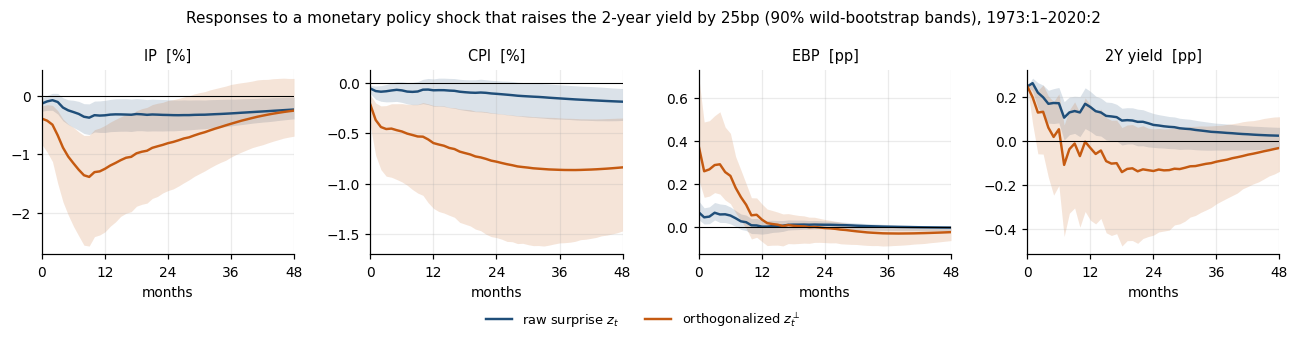

In [9]:
UNITS = ["%", "%", "pp", "pp"]
months = np.arange(H + 1)
colors = {"raw  z": BLUE, "orth z⊥": ORANGE}
labels = {"raw  z": "raw surprise $z_t$", "orth z⊥": r"orthogonalized $z_t^\perp$"}

fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True)
for i, ax in enumerate(axes):
    for name in instruments:
        lo, hi = bands[name]
        ax.fill_between(months, lo[:, i], hi[:, i], color=colors[name], alpha=0.16, lw=0)
        ax.plot(months, point[name][:, i], color=colors[name], label=labels[name])
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{VARS[i]}  [{UNITS[i]}]"); ax.set_xlim(0, H); ax.set_xticks(range(0, H + 1, 12))
    ax.set_xlabel("months")
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, frameon=False, fontsize=8.5, loc="lower center", ncol=len(labs), bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Responses to a monetary policy shock that raises the 2-year yield by 25bp (90% wild-bootstrap bands), 1973:1–2020:2", fontsize=10)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "irf_raw_vs_orth.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
def summary(r, lo, hi):
    back = next((k for k in range(1, H + 1) if r[k, 3] < 0.1 * SHOCK), None)
    return {
        "IP trough (%)": f"{r[:, 0].min():.2f}", "IP trough month": int(r[:, 0].argmin()),
        "months with IP < 0 at 90%": int((hi[:, 0] < 0).sum()),
        "CPI trough (%)": f"{r[:, 1].min():.2f}", "months with CPI < 0 at 90%": int((hi[:, 1] < 0).sum()),
        "EBP impact (pp)": f"{r[0, 2]:.3f}", "months with EBP > 0 at 90%": int((lo[:, 2] > 0).sum()),
        "2y yield: first month below 10% of impact": back, "2y yield: minimum (pp)": f"{r[:, 3].min():.2f}",
    }
tab = pd.DataFrame({labels[k]: summary(point[k], *bands[k]) for k in instruments})
tab["paper (raw / orth)"] = ["−0.35 / −1.4", "", "", "", "", "≈ 0.05 / ≈ 4× larger", "", "≈ 48 / < 12", ""]
tab

,raw surprise $z_t$,orthogonalized $z_t^\perp$,paper (raw / orth)
IP trough (%),-0.38,-1.39,−0.35 / −1.4
IP trough month,9,9,
months with IP < 0 at 90%,46,29,
CPI trough (%),-0.19,-0.87,
months with CPI < 0 at 90%,24,49,
EBP impact (pp),0.069,0.372,≈ 0.05 / ≈ 4× larger
months with EBP > 0 at 90%,8,9,
2y yield: first month below 10% of impact,48,5,≈ 48 / < 12
2y yield: minimum (pp),0.02,-0.14,


**Raw instrument (blue), the paper's left column.**
- The 2-year yield rises by 25bp and declines only slowly: it is still above a tenth of its impact after four years.
- The excess bond premium rises by about 7bp on impact (the paper reports about 5bp), stays at 5–7bp for about half a year, as in the paper, and is back near zero after about ten months.
- Industrial production falls gradually, to a trough of **−0.38% after nine months** (paper: −0.35%). It stays significantly below zero, at the 90% level, for almost the whole four years.
- The CPI declines slowly, to −0.19% after four years.

**Orthogonalized instrument (orange), the right column.**
- The 2-year yield falls below a tenth of its impact within **five months**, then slightly undershoots (−0.14pp); the paper reports a return in less than a year.
- Industrial production has a trough of **−1.39% after nine months** (paper: −1.4%), 3.7 times the raw response.
- The CPI falls by 0.87% (4.6 times) and the excess bond premium rises by 37bp on impact (5 times). This is the paper's "factor of about four".

The two columns differ **only** in the impact vector $s_1$; the VAR dynamics $B(L)$ are the same (the paper's footnote 50). Removing the Fed's predictable response to news does two things. It removes a bias of the opposite sign: good news raises rates *and* output. It also slightly lowers the impact on the yield, so the rescaling to 25bp inflates the other elements further.

**How big is the shock?** A 25bp rise in the 2-year yield corresponds roughly to a 55bp rise in the federal funds rate (footnote 51, based on Gürkaynak et al., 2005). Keep this in mind when comparing with SVARs that shock the funds rate, such as CEE (2005). The orthogonalized effects are four times the usual SVAR estimates. The paper argues that they are still plausible: they lie between those SVARs and Romer and Romer (2004), the range Coibion (2012) considers most credible.

**The price of orthogonalizing.** The orange bands are much wider: this is the weak instrument (F ≈ 2) at work. Industrial production is significantly negative for 29 months instead of 46. The point estimates are larger but far less precise, which is exactly why the paper goes on to add the Fed Chair speeches.

## 9. Sample periods (Figure 2)

Figure 2 of the paper re-estimates the raw-instrument SVAR over three samples:
- (a) the full sample 1973:1–2020:2;
- (b) Gertler and Karadi's 1979:7–2012:6;
- (c) 1988:1–2020:2, the period covered by the surprises.

This addresses Ramey's (2016) concern that post-1980s samples contain too little policy variation. In each case both the VAR and the instrument use only the months inside the sample; the 12 months before it provide the initial lags.

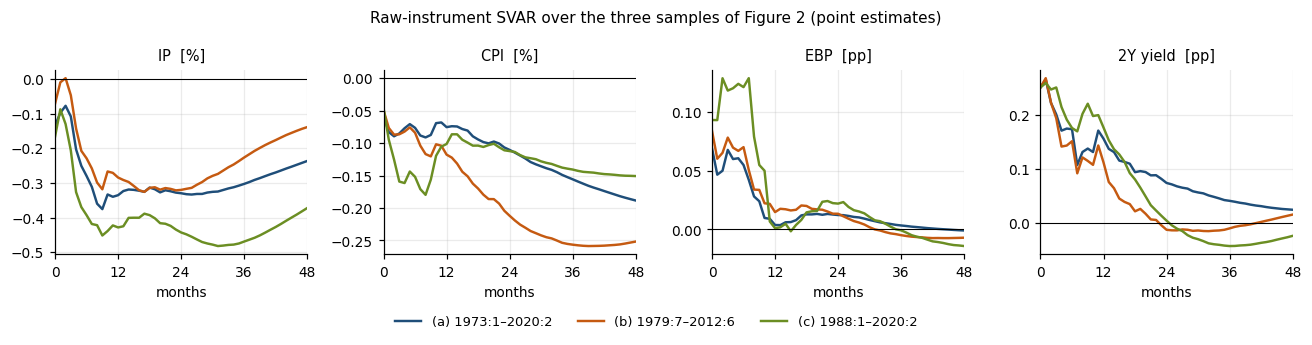

,(a) 1973:1–2020:2,(b) 1979:7–2012:6,(c) 1988:1–2020:2
IP trough (%),-0.38,-0.33,-0.48
IP trough month,9.00,17.00,31.00
CPI at 48m (%),-0.19,-0.25,-0.15
first-stage F,6.89,5.14,6.89


In [11]:
fig2_samples = {"(a) 1973:1–2020:2": ("1973-01", "2020-02"),
                "(b) 1979:7–2012:6": ("1979-07", "2012-06"),
                "(c) 1988:1–2020:2": ("1988-01", "2020-02")}
full = pd.DataFrame({"IP": 100 * np.log(monthly["IP"]), "CPI": 100 * np.log(monthly["CPI"]),
                     "EBP": monthly["EBP"], "2Y yield": monthly["2y Treas"]})
fig2, fig2_F = {}, {}
for name, (a, b) in fig2_samples.items():
    start = pd.Period(a, "M")
    d = full.loc[max(start - P, full.index[0]):b]      # 1973:1 has no pre-sample: there the first 12 months are the lags
    Yd = d.values
    Bd, Ud = estimate_var(Yd, P)
    zr = z_raw.reindex(d.index[P:])
    ok = zr.notna().values
    fig2[name] = irf(Bd, impact_vector(Ud[ok], zr.values[ok]), P, H)
    fig2_F[name] = first_stage_F(Yd, zr, P)

fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True)
for i, ax in enumerate(axes):
    for (name, r), col in zip(fig2.items(), [BLUE, ORANGE, "#6b8e23"]):
        ax.plot(months, r[:, i], color=col, label=name)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{VARS[i]}  [{UNITS[i]}]"); ax.set_xlim(0, H); ax.set_xticks(range(0, H + 1, 12)); ax.set_xlabel("months")
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, frameon=False, fontsize=8.5, loc="lower center", ncol=len(labs), bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Raw-instrument SVAR over the three samples of Figure 2 (point estimates)", fontsize=10)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "irf_sample_periods.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({n: {"IP trough (%)": r[:, 0].min(), "IP trough month": int(r[:, 0].argmin()),
                  "CPI at 48m (%)": r[H, 1], "first-stage F": fig2_F[n]} for n, r in fig2.items()}).round(2)

The three samples of Figure 2 give similar answers in the first year: industrial production falls by about 0.3–0.4% with a raw-instrument shock of 25bp. They then diverge:
- **(b)** Gertler and Karadi's sample recovers faster.
- **(c)** 1988–2020, the sample with the surprises, has a deeper and later trough (−0.48% after 31 months).

The paper describes (c) as very similar to the others, with wider bands. Our point estimates differ more in timing; we plot them without bands.

The first-stage F statistic is the same in (a) and (c). That is expected, not a coincidence: the first-stage regression uses only the months where the instrument is observed (1988–2019), and these months, with their lags, are identical in the two samples.